In [1]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

tf.config.set_visible_devices([], 'GPU')

#Définition de la longueur et de la largeur de l'image
LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

#Chargement des images
observations_entrainement = pnd.read_csv('datas/fashion-mnist_train.csv')

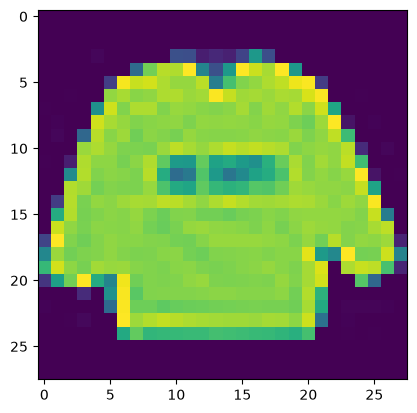

In [2]:
#On exclut la première colonne (les labels) pour constituer un tableau de pixels
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE,LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

In [3]:
#On crée des catégories à l'aide du module Keras
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:,0]))
#Répartition des données d'entrainement en données d'apprentissage et données de validation
#80% de donnée d'apprentissage et 20% de donnée de validation
X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

In [4]:
# On redimensionne les images au format 28*28 et on réalise un scaling sur les données des pixels
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0],
                                          LARGEUR_IMAGE,
                                          LONGUEUR_IMAGE, 1)
X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0],
                                    LARGEUR_IMAGE,
                                    LONGUEUR_IMAGE, 1)
X_validation = X_validation.astype('float32')
X_validation /= 255

In [5]:
#Preparation des données de tests
observations_test = pnd.read_csv('datas/fashion-mnist_test.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0],
                        LARGEUR_IMAGE,
                        LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

In [6]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

# On spécifie les dimensions de l'image d'entrée
dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

# On crée le réseau de neurones couche par couche
reseauNeurone1Convolution = Sequential()

# Ajout de la couche d'entrée
reseauNeurone1Convolution.add(Input(shape=dimentionImage))

#1- Ajout de la couche de convolution comportant
# 32 filtres de de taille 3x3 (Kernel) parcourant l'image
# Une fonction d'activation de type ReLU (Rectified Linear Activation)
# Une image d'entrée de 28px * 28 px
reseauNeurone1Convolution.add(Conv2D(32,
                                     kernel_size=(3, 3),
                                     activation='relu'))

#2- Définition de la fonction de pooling avec une fenêtre de 2px sur 2 px
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2, 2)))

#3- Ajout d'une fonction d'ignorance
reseauNeurone1Convolution.add(Dropout(0.2))

#5 - On transforme en une seule ligne
reseauNeurone1Convolution.add(Flatten())

#6 - Ajout d'un réseau de neurones composé de 128 neurones avec
# une fonction d'activation de type ReLU
reseauNeurone1Convolution.add(Dense(128, activation='relu'))

#7 - Ajout d'un réseau de neurones composé de 10 neurones avec une
# fonction d'activation de type softmax
reseauNeurone1Convolution.add(Dense(10, activation='softmax'))

In [8]:
reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy,
                                  optimizer=tf.keras.optimizers.Adam(),
                                  metrics=['accuracy'])

In [9]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    X_apprentissage,
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.8105 - loss: 0.5364 - val_accuracy: 0.8635 - val_loss: 0.3862
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.8760 - loss: 0.3533 - val_accuracy: 0.8823 - val_loss: 0.3410
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8904 - loss: 0.3136 - val_accuracy: 0.8912 - val_loss: 0.3114
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9000 - loss: 0.2854 - val_accuracy: 0.8949 - val_loss: 0.2948
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9039 - loss: 0.2683 - val_accuracy: 0.8971 - val_loss: 0.2868
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9087 - loss: 0.2513 - val_accuracy: 0.9041 - val_loss: 0.2715
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9129 - loss: 0.2437 - val_accuracy: 0.9061 - val_loss: 0.2614
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9189 - loss: 0.2255 - val_accu

In [10]:
score = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)

print('Perte (loss) :', score[0])
print('Précision (accuracy) :', score[1])

Perte (loss) : 0.2500016689300537
Précision (accuracy) : 0.9085999727249146


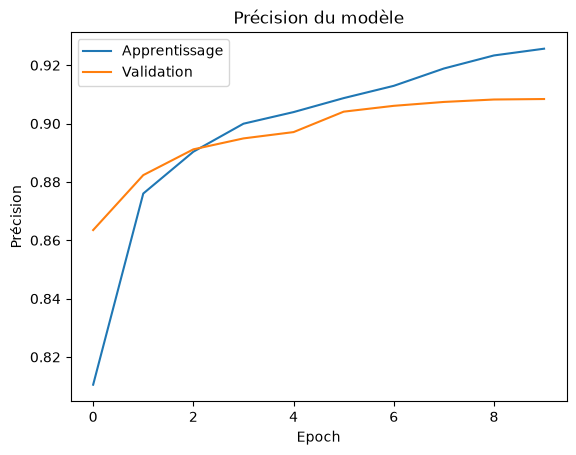

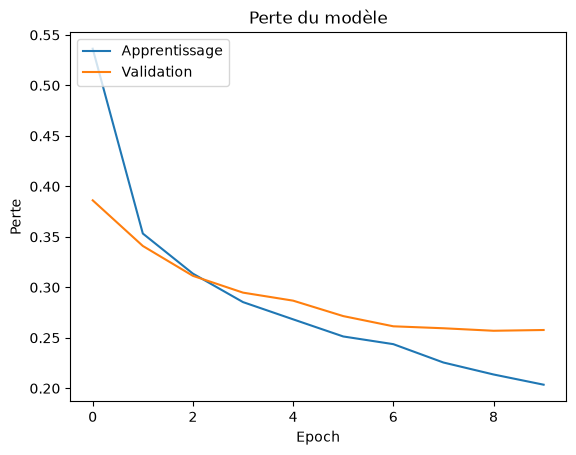

In [11]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Validation'], loc='upper left')
plt.show()

plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Perte du modèle')
plt.ylabel('Perte')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Validation'], loc='upper left')
plt.show()

In [12]:
datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    shear_range=0.3,
    height_shift_range=0.08,
    zoom_range=0.08
)

In [13]:
historique_augmentation = reseauNeurone1Convolution.fit(
    datagen.flow(X_apprentissage, y_apprentissage, batch_size=256),
    steps_per_epoch=48000 // 256,
    epochs=50,
    validation_data=datagen.flow(X_validation, y_validation, batch_size=256),
    validation_steps=12000 // 256
)

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - accuracy: 0.8250 - loss: 0.4710 - val_accuracy: 0.8457 - val_loss: 0.4200
Epoch 2/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8281 - loss: 0.4798

c:\Users\Antoine\SCHOOL\SESSION 5\TECHNOLOGIE_EMERGENTES\ATELIERS_ML\420-5G4-ML\analyse_image\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8281 - loss: 0.4798 - val_accuracy: 0.8442 - val_loss: 0.4138
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - accuracy: 0.8464 - loss: 0.4136 - val_accuracy: 0.8497 - val_loss: 0.4079
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8750 - loss: 0.3955 - val_accuracy: 0.8463 - val_loss: 0.4021
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - accuracy: 0.8533 - loss: 0.3976 - val_accuracy: 0.8607 - val_loss: 0.3784
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8672 - loss: 0.3767 - val_accuracy: 0.8650 - val_loss: 0.3718
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step - accuracy: 0.8604 - loss: 0.3785 - val_accuracy: 0.8675 - val_loss: 0.3686
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8477 - loss: 0.3568 - val_accuracy: 0.8635 - val_loss: 0.3669
Epoch 9/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.8634 - loss: 0.3664 - val_accuracy: 0.8655 - 

In [14]:
model_json = reseauNeurone1Convolution.to_json()

with open("modele/modele.json", "w") as json_file:
    json_file.write(model_json)

reseauNeurone1Convolution.save_weights("modele/modele.weights.h5")